<div dir="rtl" style="text-align:right">

# پروژهٔ نهایی: امتیازدهی ریسک اعتباری
**هدف:** ساخت مدل اولیه برای پیش‌بینی احتمال نکول مشتریان و رتبه‌بندی ریسک آن‌ها، بدون نشت اطلاعات، با تفسیرپذیری و در نظر گرفتن ماتریس هزینهٔ کسب‌وکار.

**ساختار:** ۱) پاک‌سازی   ۲) مهندسی ویژگی و پیش‌پردازش  ۳) مدل‌سازی و توضیح‌پذیری   ۴) علیت در برابر همبستگی  

## فرض‌ها و ملاحظات 
1. **برچسب:** ۰ = خوش‌حساب (اصلی ۱)، ۱ = نکول/بدحساب (اصلی ۲)؛ کلاس مثبت = نکول.
2. **EDA**  روی کل ۱۰۰۰ ردیف است زیرا هیچ تبدیل یادگیرنده‌ای نمی‌سازد و هیچ انتخاب ویژگی‌ای از آن وارد مدل نمی‌شود. **تمام** تحلیل‌های وابسته به هدف که به مدل‌سازی مرتبط‌اند فقط روی **Train** هستند.
3. کدهای `A65` (پس‌انداز) و `A124` (دارایی) «نامشخص» معنایی‌اند و به‌عنوان یک دستهٔ مستقل (و نه NaN واقعی) حفظ می‌شوند. `A14` (بدون حساب جاری) وضعیت واقعی است، نه داده گمشده؛ برای آن یک ویژگی نشانگر هم ساخته می‌شود.
4. ماتریس هزینه **مستقیماً از `german.doc` خوانده می‌شود** (هزینه به‌صورت واحد نسبی است، نه مبلغ دقیق مارک).
5. `implied_disposable_income` یک **تقریب** است: قسط ماهانه = مبلغ ÷ مدت (بدون بهره) و `installment_rate` فقط مقادیر ۱ تا ۴ دارد.
6. انتخاب مدل نهایی و cut-off فقط بر پایهٔ **Train (CV / پیش‌بینی out-of-fold)** است؛ مجموعهٔ Test فقط برای گزارش نهایی استفاده می‌شود. Test فقط ۲۰۰ ردیف بدحساب دارد، پس عدم‌قطعیت معیارها زیاد است.
7. اگر داده با متن دستور کار مغایر بود، به داده اعتماد شده و مغایرت یادداشت می‌شود (مغایرت‌ها در سلول‌های مربوط گزارش می‌شوند).

</div>

In [1]:
import os, re, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, spearmanr
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_PATH, NUMERIC_PATH, DOC_PATH = "german.data", "german.data-numeric", "german.doc"
os.makedirs("figs", exist_ok=True)
RES = {} 
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
C_MAIN, C_BAD, C_GREY = "#1f6f8b", "#c0392b", "#9aa5ab"

def rtl(text):
    """Display a Persian Markdown string right-to-left (used for text that embeds computed numbers)."""
    display(Markdown(f'<div dir="rtl" style="text-align:right">\n\n{text}\n\n</div>'))

def save(fig, name):
    fig.savefig(f"figs/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

<div dir="rtl" style="text-align:right">

## گام ۱ — پاک‌سازی داده و تحلیل اکتشافی 
### ۱-۱ بارگذاری، نام‌گذاری ستون‌ها، تبدیل هدف و خواندن ماتریس هزینه

</div>

In [2]:
#Column names (snake_case) in the order of german.doc attributes 1..20, then the target
COLS = ["checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings",
        "employment_since", "installment_rate", "personal_status_sex", "other_debtors",
        "residence_since", "property", "age", "other_installment_plans", "housing",
        "existing_credits", "job", "num_dependents", "telephone", "foreign_worker", "target_raw"]
raw = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=COLS)
assert raw.shape == (1000, 21)
#target: 0 = good (original 1), 1 = default/bad (original 2)
raw["target"] = (raw["target_raw"] == 2).astype(int)
FEATURES = COLS[:-1]

#Cross-check with the reference numeric file (same rows, same target column)
ref = pd.read_csv(NUMERIC_PATH, sep=r"\s+", header=None)
print("german.data-numeric shape:", ref.shape, "| target identical to raw file:",
      bool((ref.iloc[:, -1].values == raw["target_raw"].values).all()))

#Cost matrix read directly from german.doc (rows = actual, cols = predicted; 1 = good, 2 = bad)
doc = open(DOC_PATH, encoding="latin-1").read()
m = re.search(r"\n\s*1\s+0\s+(\d+)\s*\n[-\s]*\n\s*2\s+(\d+)\s+0", doc)
COST_FP, COST_FN = int(m.group(1)), int(m.group(2))   # FP: good rejected | FN: bad approved
print(f"Cost matrix from german.doc -> reject a good customer (FP) = {COST_FP}, approve a bad customer (FN) = {COST_FN}")

#Readable labels (display copy only; the modelling frame keeps the original codes)
LABELS = {
 "checking_status": {"A11":"< 0 DM","A12":"0-200 DM","A13":">= 200 DM / salary","A14":"no checking account"},
 "credit_history": {"A30":"no credits / all paid","A31":"all paid at this bank","A32":"existing paid duly","A33":"delay in past","A34":"critical / other credits"},
 "purpose": {"A40":"car (new)","A41":"car (used)","A42":"furniture","A43":"radio/TV","A44":"appliances","A45":"repairs","A46":"education","A47":"vacation","A48":"retraining","A49":"business","A410":"others"},
 "savings": {"A61":"< 100 DM","A62":"100-500 DM","A63":"500-1000 DM","A64":">= 1000 DM","A65":"unknown / none"},
 "employment_since": {"A71":"unemployed","A72":"< 1 yr","A73":"1-4 yrs","A74":"4-7 yrs","A75":">= 7 yrs"},
 "personal_status_sex": {"A91":"male div/sep","A92":"female div/sep/married","A93":"male single","A94":"male married/widowed","A95":"female single"},
 "other_debtors": {"A101":"none","A102":"co-applicant","A103":"guarantor"},
 "property": {"A121":"real estate","A122":"savings agr./insurance","A123":"car/other","A124":"unknown / none"},
 "other_installment_plans": {"A141":"bank","A142":"stores","A143":"none"},
 "housing": {"A151":"rent","A152":"own","A153":"for free"},
 "job": {"A171":"unskilled non-resident","A172":"unskilled resident","A173":"skilled","A174":"management/highly qualified"},
 "telephone": {"A191":"none","A192":"yes"},
 "foreign_worker": {"A201":"yes","A202":"no"},
}
CAT = list(LABELS.keys())
NUM = [c for c in FEATURES if c not in CAT]
df_disp = raw.copy()
for c, mp in LABELS.items():
    df_disp[c] = df_disp[c].map(mp)
df_disp["target"] = df_disp["target"].map({0: "good", 1: "bad"})
display(df_disp.head())

german.data-numeric shape: (1000, 25) | target identical to raw file: True
Cost matrix from german.doc -> reject a good customer (FP) = 1, approve a bad customer (FN) = 5


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target_raw,target
0,< 0 DM,6,critical / other credits,radio/TV,1169,unknown / none,>= 7 yrs,4,male single,none,...,67,none,own,2,skilled,1,yes,yes,1,good
1,0-200 DM,48,existing paid duly,radio/TV,5951,< 100 DM,1-4 yrs,2,female div/sep/married,none,...,22,none,own,1,skilled,1,none,yes,2,bad
2,no checking account,12,critical / other credits,education,2096,< 100 DM,4-7 yrs,2,male single,none,...,49,none,own,1,unskilled resident,2,none,yes,1,good
3,< 0 DM,42,existing paid duly,furniture,7882,< 100 DM,4-7 yrs,2,male single,guarantor,...,45,none,for free,1,skilled,2,none,yes,1,good
4,< 0 DM,24,delay in past,car (new),4870,< 100 DM,1-4 yrs,3,male single,none,...,53,none,for free,2,skilled,2,none,yes,2,bad


<div dir="rtl" style="text-align:right">

### ۱-۲ ابعاد، انواع متغیر، مقادیر گمشده و عدم‌توازن کلاس‌ها

</div>

In [3]:
n, y_all = len(raw), raw["target"]
n_bad, n_good = int(y_all.sum()), int((1 - y_all).sum())
IR = n_good / n_bad
real_nan = int(raw[FEATURES].isna().sum().sum())
unk_sav = int((raw.savings == "A65").sum()); unk_prop = int((raw.property == "A124").sum())
no_chk = int((raw.checking_status == "A14").sum())
print(f"Samples: {n} | features: {len(FEATURES)} | numeric: {len(NUM)} {NUM}")
print(f"Categorical: {len(CAT)}")
print(f"Real NaN cells: {real_nan}")
print(f"Semantic 'unknown': savings=A65 -> {unk_sav} rows ({unk_sav/n:.1%}); property=A124 -> {unk_prop} rows ({unk_prop/n:.1%})")
print(f"(checking_status=A14 'no checking account' -> {no_chk} rows: a genuine status, not a missing value)")
print(f"Classes: good={n_good}, bad={n_bad} | default rate={n_bad/n:.1%} | Imbalance Ratio (good:bad)={IR:.2f}:1")
print("Dtypes:", raw[FEATURES].dtypes.value_counts().to_dict())
display(raw[NUM].describe().T.round(2))
RES["overview"] = dict(n=n, n_features=len(FEATURES), n_num=len(NUM), n_cat=len(CAT), real_nan=real_nan,
                       unk_savings=unk_sav, unk_property=unk_prop, no_checking=no_chk,
                       n_good=n_good, n_bad=n_bad, imbalance_ratio=IR, cost_fp=COST_FP, cost_fn=COST_FN)

Samples: 1000 | features: 20 | numeric: 7 ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical: 13
Real NaN cells: 0
Semantic 'unknown': savings=A65 -> 183 rows (18.3%); property=A124 -> 154 rows (15.4%)
(checking_status=A14 'no checking account' -> 394 rows: a genuine status, not a missing value)
Classes: good=700, bad=300 | default rate=30.0% | Imbalance Ratio (good:bad)=2.33:1
Dtypes: {dtype('O'): 13, dtype('int64'): 7}


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0


<div dir="rtl" style="text-align:right">

### ۱-۳ توزیع مبلغ وام و مدت + داده‌های پرت (قانون IQR)
**تصمیم دربارهٔ پرت‌ها: نگه‌داشتن (Keep) بدون Cap.** دلایل: (الف) مقادیر بزرگ وام/مدت واقعی‌اند و به‌صورت ذاتی با ریسک مرتبط‌اند (نرخ نکول آن‌ها در خروجی پایین گزارش می‌شود)؛ (ب) مدل‌های درختی نسبت به مقیاس و مقادیر حدی مقاوم‌اند؛ (ج) Cap کردن اطلاعات ریسکی مهم را حذف می‌کند و n=۱۰۰۰ اجازهٔ حذف مشاهدات را نمی‌دهد.

</div>

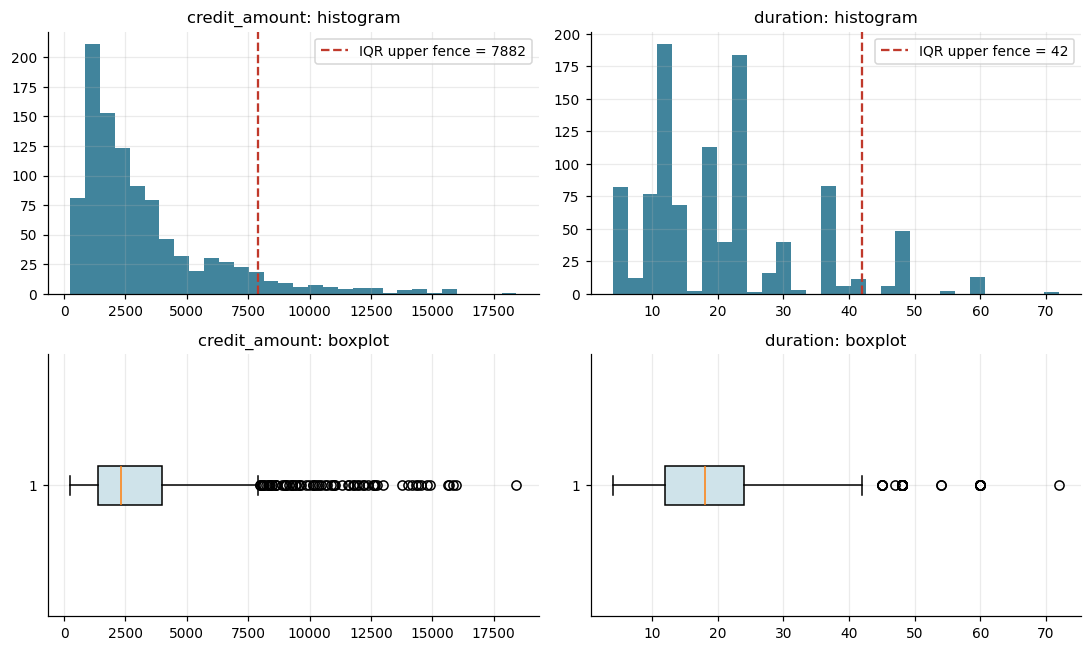

                  lower     upper  n_outliers  default_rate_outliers  \
credit_amount -2544.625  7882.375        72.0                  0.542   
duration         -6.000    42.000        70.0                  0.571   

               default_rate_rest   skew  
credit_amount              0.281  1.950  
duration                   0.280  1.094  


In [4]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
out_info = {}
for j, col in enumerate(["credit_amount", "duration"]):
    lo, hi = iqr_bounds(raw[col]); flag = (raw[col] < lo) | (raw[col] > hi)
    out_info[col] = dict(lower=lo, upper=hi, n_outliers=int(flag.sum()),
                         default_rate_outliers=float(raw.loc[flag, "target"].mean()),
                         default_rate_rest=float(raw.loc[~flag, "target"].mean()),
                         skew=float(raw[col].skew()))
    ax[0, j].hist(raw[col], bins=30, color=C_MAIN, alpha=.85); ax[0, j].axvline(hi, color=C_BAD, ls="--", label=f"IQR upper fence = {hi:.0f}")
    ax[0, j].set_title(f"{col}: histogram"); ax[0, j].legend()
    ax[1, j].boxplot(raw[col], vert=False, patch_artist=True, boxprops=dict(facecolor="#cfe3ea")); ax[1, j].set_title(f"{col}: boxplot")
fig.tight_layout(); save(fig, "eda_dist_amount_duration")
print(pd.DataFrame(out_info).T.round(3))
RES["outliers"] = out_info

<div dir="rtl" style="text-align:right">

### ۱-۴ همبستگی و ارتباط با هدف (Cramér's V، نرخ نکول هر دسته؛ تمرکز بر checking_status و credit_history)

</div>

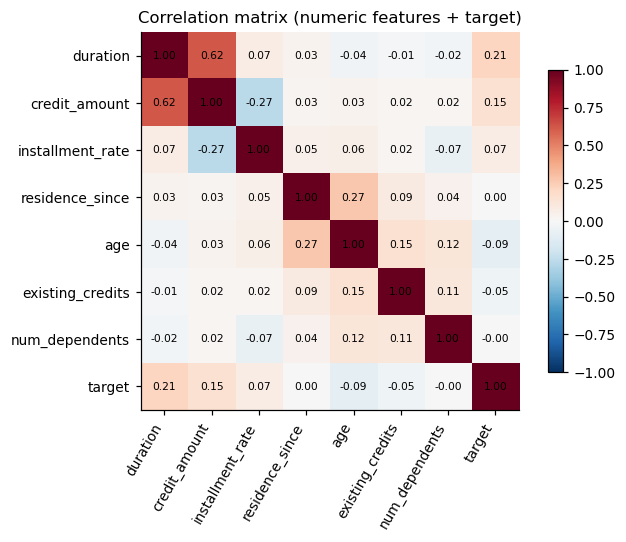

duration            0.215
credit_amount       0.155
age                -0.091
installment_rate    0.072
existing_credits   -0.046
num_dependents     -0.003
residence_since     0.003
Name: target, dtype: float64


,feature,cramers_v,chi2_p
0,checking_status,0.3517,0.0000
1,credit_history,0.2484,0.0000
3,savings,0.1900,0.0000
2,purpose,0.1826,0.0001
7,property,0.1540,0.0000
4,employment_since,0.1355,0.0010
9,housing,0.1349,0.0001
8,other_installment_plans,0.1133,0.0016
5,personal_status_sex,0.0980,0.0222
12,foreign_worker,0.0821,0.0094


,default_rate,count
checking_status,,
< 0 DM,0.493,274
0-200 DM,0.390,269
>= 200 DM / salary,0.222,63
no checking account,0.117,394


,default_rate,count
credit_history,,
no credits / all paid,0.625,40
all paid at this bank,0.571,49
existing paid duly,0.319,530
delay in past,0.318,88
critical / other credits,0.171,293


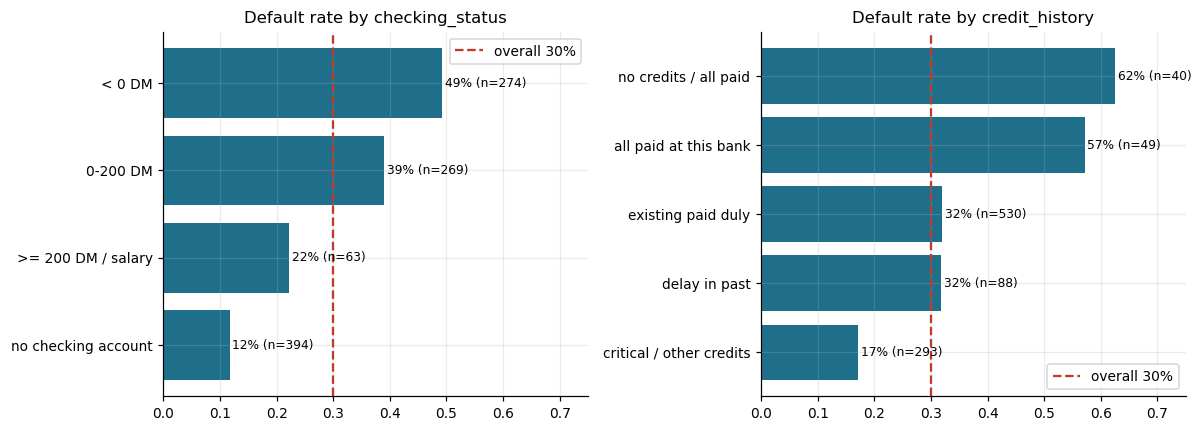

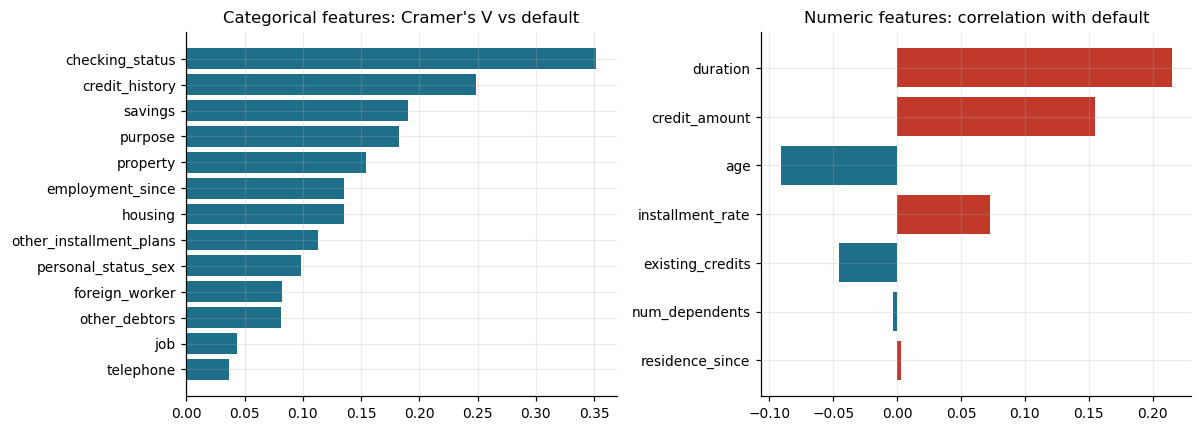

<div dir="rtl" style="text-align:right">

**نتیجه‌گیری EDA (از کدِ اجراشده):** بیشترین ارتباط با نکول در متغیرهای دسته‌ای به ترتیب مربوط به
`checking_status` (V=0.352)، `credit_history` (V=0.248) و `savings` (V=0.190) است؛
در متغیرهای عددی `duration` (r=0.215) و `credit_amount` (r=0.155) بیشترین همبستگی را دارند.
نرخ نکول در گروه `< 0 DM` حساب جاری برابر 49.3% و در گروه «بدون حساب جاری» برابر 11.7% است (میانگین کل 30.0%).


</div>

In [5]:
#numeric correlation matrix (Pearson; with the 0/1 target it is the point-biserial correlation)
corr = raw[NUM + ["target"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=.8); ax.set_title("Correlation matrix (numeric features + target)"); fig.tight_layout(); save(fig, "eda_corr")
num_corr = corr["target"].drop("target").sort_values(key=abs, ascending=False)
print(num_corr.round(3))

#categorical: Cramer's V + chi-square p-value against the target
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2, p, _, _ = chi2_contingency(t, correction=False)
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), p
cv_tab = pd.DataFrame([(c, *cramers_v(raw[c], raw["target"])) for c in CAT], columns=["feature", "cramers_v", "chi2_p"]).sort_values("cramers_v", ascending=False)
display(cv_tab.round(4))

#default rate per category (display labels)
def default_rate_table(col):
    t = df_disp.assign(bad=raw["target"]).groupby(col)["bad"].agg(["mean", "count"]).rename(columns={"mean": "default_rate"})
    return t.sort_values("default_rate", ascending=False)
overall = raw["target"].mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(ax, ["checking_status", "credit_history"]):
    t = default_rate_table(col); display(t.round(3))
    a.barh(t.index[::-1], t["default_rate"][::-1], color=C_MAIN); a.axvline(overall, color=C_BAD, ls="--", label=f"overall {overall:.0%}")
    for yy, (r, c_) in enumerate(zip(t["default_rate"][::-1], t["count"][::-1])): a.text(r + .005, yy, f"{r:.0%} (n={c_})", va="center", fontsize=8)
    a.set_title(f"Default rate by {col}"); a.set_xlim(0, .75); a.legend()
fig.tight_layout(); save(fig, "eda_default_by_checking_history")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(cv_tab.feature[::-1], cv_tab.cramers_v[::-1], color=C_MAIN); ax[0].set_title("Categorical features: Cramer's V vs default")
ax[1].barh(num_corr.index[::-1], num_corr.values[::-1], color=[C_BAD if v > 0 else C_MAIN for v in num_corr.values[::-1]]); ax[1].set_title("Numeric features: correlation with default")
fig.tight_layout(); save(fig, "eda_association_ranking")
RES["eda"] = dict(cramers_v=cv_tab.set_index("feature")["cramers_v"].to_dict(), chi2_p=cv_tab.set_index("feature")["chi2_p"].to_dict(),
                  num_corr=num_corr.to_dict(),
                  checking=default_rate_table("checking_status").to_dict("index"),
                  history=default_rate_table("credit_history").to_dict("index"))
top_c = cv_tab.head(3).feature.tolist(); top_n = num_corr.head(2)
rtl(f"""**نتیجه‌گیری EDA (از کدِ اجراشده):** بیشترین ارتباط با نکول در متغیرهای دسته‌ای به ترتیب مربوط به
`{top_c[0]}` (V={cv_tab.cramers_v.iloc[0]:.3f})، `{top_c[1]}` (V={cv_tab.cramers_v.iloc[1]:.3f}) و `{top_c[2]}` (V={cv_tab.cramers_v.iloc[2]:.3f}) است؛
در متغیرهای عددی `{top_n.index[0]}` (r={top_n.iloc[0]:.3f}) و `{top_n.index[1]}` (r={top_n.iloc[1]:.3f}) بیشترین همبستگی را دارند.
نرخ نکول در گروه `< 0 DM` حساب جاری برابر {RES['eda']['checking']['< 0 DM']['default_rate']:.1%} و در گروه «بدون حساب جاری» برابر {RES['eda']['checking']['no checking account']['default_rate']:.1%} است (میانگین کل {overall:.1%}).
""")

<div dir="rtl" style="text-align:right">

## گام ۲ — مهندسی ویژگی و پیش‌پردازش (بدون نشت)
### ۲-۱ تقسیم Stratified ‏80/20 با `random_state=42` — **قبل از هرگونه fit**

</div>

In [6]:
# Stratified 80/20 split BEFORE any fitting. From here on, everything that learns anything uses X_train only.
X = raw[FEATURES].copy(); y = raw["target"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, f"default rate {y_train.mean():.3f} | Test:", X_test.shape, f"default rate {y_test.mean():.3f}")
RES["split"] = dict(n_train=len(X_train), n_test=len(X_test), bad_train=int(y_train.sum()), bad_test=int(y_test.sum()))

Train: (800, 20) default rate 0.300 | Test: (200, 20) default rate 0.300


<div dir="rtl" style="text-align:right">

### ۲-۲ Pipeline پیش‌پردازش (فقط روی Train fit می‌شود)
**منطق کدگذاری:**
- **Ordinal (دارای ترتیب):** `checking_status` (<0 < 0–200 < ≥200)، `savings` (۴ سطح پس‌انداز)، `employment_since` (بیکار < ... < ≥۷ سال)، `job` (غیرماهر < ماهر < مدیر/متخصص). مقادیر `A14` (بدون حساب جاری) و `A65` (پس‌انداز نامشخص) در ترتیب نمی‌گنجند؛ کد آن‌ها `-1` می‌شود و یک ویژگی نشانگر جداگانه (`no_checking_account`، `savings_unknown`) هم دارند تا اثرشان جدا از ترتیب یاد گرفته شود.
- **One-hot (اسمی):** `credit_history`، `purpose`، `personal_status_sex`، `other_debtors`، `property` (شامل «نامشخص» A124 به‌عنوان یک دستهٔ معنادار)، `other_installment_plans`، `housing`، `telephone`، `foreign_worker`. دستهٔ ناشناخته در زمان تست نادیده گرفته می‌شود (`handle_unknown='ignore'`).
- **عددی:** imputer میانه (هیچ NaN واقعی وجود ندارد ولی برای استحکام Pipeline حفظ شده)؛ **Scaling اعمال نمی‌شود** چون هر دو مدل درختی‌اند و نسبت به مقیاس ناوردا هستند.
- ویژگی‌های مالی در یک مرحلهٔ **بدون‌حالت** (stateless؛ چیزی از داده یاد نمی‌گیرد) داخل Pipeline ساخته می‌شوند، پس نشت ممکن نیست.

### ۲-۳ ویژگی‌های مالی ساخته‌شده (فرمول، منطق و جهت ریسک مورد انتظار)
| ویژگی | فرمول | منطق | جهت ریسک مورد انتظار |
|---|---|---|---|
| `monthly_payment` | credit_amount ÷ duration | بار بازپرداخت ماهانه (بدون بهره) | بیشتر ⇒ ریسک بیشتر (+) |
| `implied_disposable_income` | monthly_payment ÷ (installment_rate/100) | چون installment_rate «درصد قسط از درآمد قابل‌تصرف» است، این نسبت تقریبی از درآمد قابل‌تصرف می‌دهد (نبود متغیر درآمد را جبران می‌کند) | بیشتر ⇒ ریسک کمتر (−) |
| `stability_flag` | اشتغال ≥۴ سال **و** مالک مسکن | شاخص ثبات رفتاری/مالی | ۱ ⇒ ریسک کمتر (−) |

> عمداً از `credit_amount_per_age` استفاده نشد تا ویژگی‌های مهندسی‌شده به متغیر حساس `age` وابسته نباشند و آزمون حذف متغیرهای حساس تمیز بماند.

</div>

In [7]:
SENSITIVE = ["personal_status_sex", "age", "foreign_worker"]
ORD_ORDER = {  # ordinal logic: ordered from "weakest" to "strongest" financial position
    "checking_status": ["A11", "A12", "A13"],                 # <0 < 0-200 < >=200 ; A14 (no account) -> -1 + separate flag
    "savings": ["A61", "A62", "A63", "A64"],                  # more savings = higher; A65 (unknown) -> -1 + separate flag
    "employment_since": ["A71", "A72", "A73", "A74", "A75"],  # longer tenure = higher
    "job": ["A171", "A172", "A173", "A174"],                  # more skilled / senior = higher
}
NOMINAL = [c for c in CAT if c not in ORD_ORDER]

class StatelessFeatures(BaseEstimator, TransformerMixin):
    """Row-wise financial features + 'unknown' flags. Nothing is learned from data -> no leakage possible."""
    def fit(self, X, y=None): return self
    def transform(self, X):
        X = X.copy()
        # (1) monthly_payment = credit_amount / duration  | risk: higher -> riskier (bigger repayment burden)
        X["monthly_payment"] = X["credit_amount"] / X["duration"]
        # (2) implied_disposable_income = monthly_payment / (installment_rate/100)
        #     installment_rate = instalment as % of disposable income -> income proxy | risk: higher -> safer
        X["implied_disposable_income"] = X["monthly_payment"] / (X["installment_rate"] / 100.0)
        # (3) stability_flag = employed >= 4 years AND owns housing | risk: 1 -> safer
        X["stability_flag"] = (X["employment_since"].isin(["A74", "A75"]) & (X["housing"] == "A152")).astype(int)
        # semantic-missing flags (A14 = no checking account, A65 = unknown savings, A124 handled by one-hot)
        X["no_checking_account"] = (X["checking_status"] == "A14").astype(int)
        X["savings_unknown"] = (X["savings"] == "A65").astype(int)
        return X

ENGINEERED = ["monthly_payment", "implied_disposable_income", "stability_flag"]
FLAGS = ["no_checking_account", "savings_unknown"]

def make_preprocessor(drop_sensitive=False, use_fe=True, scale=False):
    num = [c for c in NUM if not (drop_sensitive and c in SENSITIVE)] + (ENGINEERED if use_fe else []) + FLAGS
    nom = [c for c in NOMINAL if not (drop_sensitive and c in SENSITIVE)]
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    ct = ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OrdinalEncoder(categories=list(ORD_ORDER.values()), handle_unknown="use_encoded_value", unknown_value=-1))]),
         list(ORD_ORDER.keys())),
        ("nom", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("enc", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]), nom),
    ], remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("fe", StatelessFeatures()), ("prep", ct)])

# scale=False: BOTH models are tree-based (invariant to monotone scaling) so no scaler is applied;
# the flag exists so that a scale-sensitive model could be added without touching the rest of the code.
demo = make_preprocessor().fit(X_train)
print("Transformed feature count:", len(demo[-1].get_feature_names_out()))
display(pd.DataFrame(demo.transform(X_train.head(3)), columns=demo[-1].get_feature_names_out()).T.head(30))

Transformed feature count: 50


,0,1,2
duration,36.000000,12.0,36.000000
credit_amount,8335.000000,804.0,5371.000000
installment_rate,3.000000,4.0,3.000000
residence_since,4.000000,4.0,2.000000
age,47.000000,38.0,28.000000
existing_credits,1.000000,1.0,2.000000
num_dependents,1.000000,1.0,1.000000
monthly_payment,231.527778,67.0,149.194444
implied_disposable_income,7717.592593,1675.0,4973.148148
stability_flag,0.000000,1.0,0.000000


<div dir="rtl" style="text-align:right">

### ۲-۴ بررسی تجربی جهت اثر ویژگی‌های مهندسی‌شده (Train)

</div>

In [8]:
#Empirical check of the engineered features, on TRAIN only
tr = StatelessFeatures().transform(X_train).assign(bad=y_train.values)
expected = {"monthly_payment": "higher -> more default (+)", "implied_disposable_income": "higher -> less default (-)", "stability_flag": "1 -> less default (-)"}
rows = []
for f in ENGINEERED:
    auc = roc_auc_score(tr.bad, tr[f]); rho = spearmanr(tr[f], tr.bad)[0]
    if f == "stability_flag":
        g = tr.groupby(f).bad.mean(); detail = f"flag=0: {g[0]:.1%}, flag=1: {g[1]:.1%}"
    else:
        q = pd.qcut(tr[f], 4, labels=["Q1(low)", "Q2", "Q3", "Q4(high)"]); g = tr.groupby(q).bad.mean(); detail = " | ".join(f"{k}: {v:.1%}" for k, v in g.items())
    rows.append(dict(feature=f, expected=expected[f], AUC_vs_default=auc, spearman=rho, default_rate_by_bin=detail))
fe_tab = pd.DataFrame(rows); display(fe_tab.round(3))
RES["fe_check"] = fe_tab.to_dict("records")
fe_df = pd.DataFrame({"feature": fe_tab.feature, "auc": fe_tab.AUC_vs_default}); 
rtl("**بررسی تجربی ویژگی‌های مهندسی‌شده (فقط روی Train):**\n\n" + "\n".join(
    f"- `{r['feature']}`: انتظار نظری = {r['expected']}؛ مشاهده‌شده: AUC={r['AUC_vs_default']:.3f}، Spearman={r['spearman']:.3f} → "
    + ("هم‌جهت با انتظار" if (r['AUC_vs_default'] - .5) * (1 if r['feature'] == 'monthly_payment' else -1) > 0 else "**خلاف انتظار / بدون اثر معنی‌دار**") + f" ({r['default_rate_by_bin']})"
    for r in RES["fe_check"]))

rtl("**نکته:** `monthly_payment` برخلاف انتظار نظری رابطهٔ منفی ضعیفی با نکول دارد؛ چون مبلغ ÷ مدت، اثر «مدت طولانی» (که قوی‌ترین عامل ریسک است) را خنثی می‌کند: وام‌های کوتاه‌مدت قسط ماهانهٔ بالاتری دارند ولی ریسک کمتری دارند. این یافته بدون تغییر گزارش می‌شود و ویژگی در مدل نگه داشته شده است تا اثر آن در آزمون حذف ویژگی‌ها سنجیده شود.")

,feature,expected,AUC_vs_default,spearman,default_rate_by_bin
0,monthly_payment,higher -> more default (+),0.434,-0.105,Q1(low): 40.0% | Q2: 28.0% | Q3: 26.0% | Q4(hi...
1,implied_disposable_income,higher -> less default (-),0.436,-0.102,Q1(low): 37.0% | Q2: 31.0% | Q3: 26.0% | Q4(hi...
2,stability_flag,1 -> less default (-),0.423,-0.154,"flag=0: 34.6%, flag=1: 19.3%"


<div dir="rtl" style="text-align:right">

**بررسی تجربی ویژگی‌های مهندسی‌شده (فقط روی Train):**

- `monthly_payment`: انتظار نظری = higher -> more default (+)؛ مشاهده‌شده: AUC=0.434، Spearman=-0.105 → **خلاف انتظار / بدون اثر معنی‌دار** (Q1(low): 40.0% | Q2: 28.0% | Q3: 26.0% | Q4(high): 26.0%)
- `implied_disposable_income`: انتظار نظری = higher -> less default (-)؛ مشاهده‌شده: AUC=0.436، Spearman=-0.102 → هم‌جهت با انتظار (Q1(low): 37.0% | Q2: 31.0% | Q3: 26.0% | Q4(high): 26.0%)
- `stability_flag`: انتظار نظری = 1 -> less default (-)؛ مشاهده‌شده: AUC=0.423، Spearman=-0.154 → هم‌جهت با انتظار (flag=0: 34.6%, flag=1: 19.3%)

</div>

<div dir="rtl" style="text-align:right">

**نکته:** `monthly_payment` برخلاف انتظار نظری رابطهٔ منفی ضعیفی با نکول دارد؛ چون مبلغ ÷ مدت، اثر «مدت طولانی» (که قوی‌ترین عامل ریسک است) را خنثی می‌کند: وام‌های کوتاه‌مدت قسط ماهانهٔ بالاتری دارند ولی ریسک کمتری دارند. این یافته بدون تغییر گزارش می‌شود و ویژگی در مدل نگه داشته شده است تا اثر آن در آزمون حذف ویژگی‌ها سنجیده شود.

</div>

<div dir="rtl" style="text-align:right">

### ۲-۵ سه ویژگی خام با بیشترین قدرت تفکیک خوش‌حساب/بدحساب
معیار: **Information Value (IV)** از اعتبارسنجی اعتباری (WoE روی Train)؛ ویژگی‌های عددی با ۵ چندک گسسته می‌شوند.

</div>

,IV,strength
checking_status,0.609,very strong
credit_history,0.262,medium
savings,0.214,medium
duration,0.213,medium
purpose,0.150,medium
property,0.145,medium
employment_since,0.124,medium
other_installment_plans,0.091,weak
housing,0.089,weak
credit_amount,0.065,weak


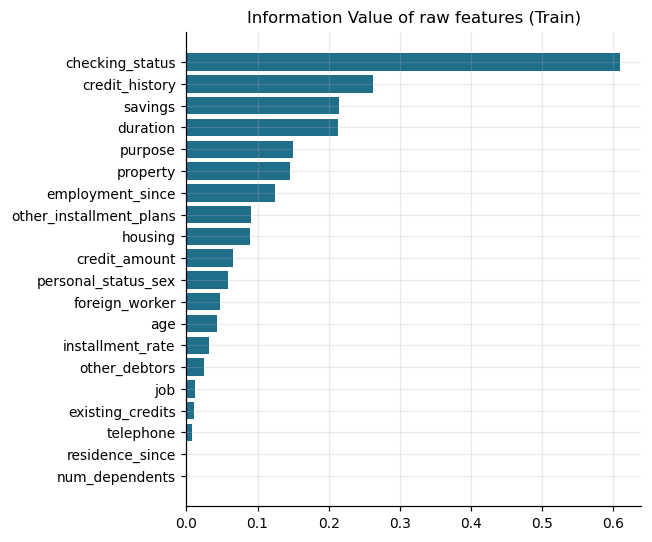

<div dir="rtl" style="text-align:right">

**سه ویژگی خامِ دارای بیشترین قدرت تفکیک (بر اساس IV روی Train):**

- `checking_status` (IV=0.609): بالاترین نرخ نکول در «< 0 DM» = 47.9% (n=219) در برابر پایین‌ترین در «no checking account» = 12.0% (n=316).
- `credit_history` (IV=0.262): بالاترین نرخ نکول در «no credits / all paid» = 61.3% (n=31) در برابر پایین‌ترین در «critical / other credits» = 17.5% (n=240).
- `savings` (IV=0.214): بالاترین نرخ نکول در «< 100 DM» = 36.4% (n=475) در برابر پایین‌ترین در «>= 1000 DM» = 12.2% (n=41).

</div>

In [9]:
#Which RAW features separate good vs bad the most? Information Value (IV) with WoE, TRAIN only
def information_value(x, yv, bins=5):
    if x.dtype.kind in "if" and x.nunique() > 10: xb = pd.qcut(x, bins, duplicates="drop")
    else: xb = x.astype(str)
    t = pd.crosstab(xb, yv) + 0.5; d = t / t.sum()
    return float(((d[0] - d[1]) * np.log(d[0] / d[1])).sum())
iv = pd.Series({c: information_value(X_train[c], y_train) for c in FEATURES}).sort_values(ascending=False)
iv_tab = pd.DataFrame({"IV": iv, "strength": pd.cut(iv, [-1, .02, .1, .3, .5, 9], labels=["useless", "weak", "medium", "strong", "very strong"])})
display(iv_tab.round(3))
fig, ax = plt.subplots(figsize=(6, 5)); ax.barh(iv.index[::-1], iv.values[::-1], color=C_MAIN); ax.set_title("Information Value of raw features (Train)")
fig.tight_layout(); save(fig, "iv_raw_features")
top3 = iv.head(3).index.tolist()
RES["iv"] = iv.to_dict(); RES["top3"] = top3
lines = []
for f in top3:
    if f in CAT:
        g = df_disp.loc[X_train.index].assign(bad=y_train).groupby(f).bad.agg(["mean", "count"]); hi, lo = g["mean"].idxmax(), g["mean"].idxmin()
        lines.append(f"- `{f}` (IV={iv[f]:.3f}): بالاترین نرخ نکول در «{hi}» = {g.loc[hi,'mean']:.1%} (n={g.loc[hi,'count']}) در برابر پایین‌ترین در «{lo}» = {g.loc[lo,'mean']:.1%} (n={g.loc[lo,'count']}).")
    else:
        auc = roc_auc_score(y_train, X_train[f]); lines.append(f"- `{f}` (IV={iv[f]:.3f}): AUC تک‌متغیره = {auc:.3f}؛ میانگین در بدحساب‌ها {X_train.loc[y_train==1,f].mean():.1f} در برابر {X_train.loc[y_train==0,f].mean():.1f} در خوش‌حساب‌ها.")
RES["top3_text"] = lines
rtl("**سه ویژگی خامِ دارای بیشترین قدرت تفکیک (بر اساس IV روی Train):**\n\n" + "\n".join(lines))

<div dir="rtl" style="text-align:right">

## گام ۳ — مدل‌سازی و توضیح‌پذیری
### ۳-۱ تنظیم هایپرپارامتر (Stratified 5-fold CV روی Train، معیار PR-AUC و گزارش ROC-AUC)
- **Baseline:** درخت تصمیم با عمق محدود (Grid روی `max_depth`، `min_samples_leaf`، `criterion`) و `class_weight='balanced'`.
- **Challenger:** **XGBoost** (نصب است) با جستجوی تصادفی ۴۰ ترکیب و `scale_pos_weight ∈ {1، نسبت neg/pos در Train}`.
- Test در هیچ انتخابی دخالت ندارد.

</div>

In [10]:
from xgboost import XGBClassifier
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)       # used for hyper-parameter tuning (Train only)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}
SPW = float((y_train == 0).sum() / (y_train == 1).sum())                # neg/pos ratio computed on Train only
print(f"scale_pos_weight candidate (Train neg/pos) = {SPW:.3f}")

# depth capped at 6 for interpretability and overfitting control
DT_GRID = {"model__max_depth": [2, 3, 4, 5, 6], "model__min_samples_leaf": [5, 10, 20, 30, 50], "model__criterion": ["gini", "entropy"]}
XGB_GRID = {"model__n_estimators": [100, 200, 300], "model__max_depth": [2, 3, 4, 5], "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
            "model__subsample": [0.6, 0.8, 1.0], "model__colsample_bytree": [0.5, 0.7, 0.9, 1.0], "model__min_child_weight": [1, 3, 5, 10],
            "model__reg_lambda": [1, 5, 10], "model__gamma": [0, 1], "model__scale_pos_weight": [1.0, SPW]}

def tune_models(drop_sensitive=False, use_fe=True):
    """Tunes Baseline (Decision Tree) and Challenger (XGBoost) with stratified 5-fold CV on TRAIN only (refit on PR-AUC)."""
    dt = GridSearchCV(Pipeline([("pre", make_preprocessor(drop_sensitive, use_fe)),
                                ("model", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
                      DT_GRID, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=2).fit(X_train, y_train)
    xg = RandomizedSearchCV(Pipeline([("pre", make_preprocessor(drop_sensitive, use_fe)),
                                      ("model", XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=SEED))]),
                            XGB_GRID, n_iter=40, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=2, random_state=SEED).fit(X_train, y_train)
    return dt, xg

dt_search, xgb_search = tune_models()
def cv_summary(s):
    i = s.best_index_; return dict(cv_pr_auc=s.cv_results_["mean_test_pr_auc"][i], cv_pr_auc_sd=s.cv_results_["std_test_pr_auc"][i],
                                   cv_roc_auc=s.cv_results_["mean_test_roc_auc"][i], cv_roc_auc_sd=s.cv_results_["std_test_roc_auc"][i])
for nm, s in [("Decision Tree (baseline)", dt_search), ("XGBoost (challenger)", xgb_search)]:
    print(nm, {k.replace("model__", ""): v for k, v in s.best_params_.items()}); print("   CV:", {k: round(v, 4) for k, v in cv_summary(s).items()})
RES["tuning"] = {"dt": dict(params=dt_search.best_params_, **cv_summary(dt_search)), "xgb": dict(params={k: (float(v) if not isinstance(v, str) else v) for k, v in xgb_search.best_params_.items()}, **cv_summary(xgb_search))}
MODELS = {"Decision Tree": dt_search.best_estimator_, "XGBoost": xgb_search.best_estimator_}   # refit on full Train

scale_pos_weight candidate (Train neg/pos) = 2.333
Decision Tree (baseline) {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 10}
   CV: {'cv_pr_auc': np.float64(0.4916), 'cv_pr_auc_sd': np.float64(0.0551), 'cv_roc_auc': np.float64(0.7025), 'cv_roc_auc_sd': np.float64(0.0433)}
XGBoost (challenger) {'subsample': 0.6, 'scale_pos_weight': 2.3333333333333335, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.9}
   CV: {'cv_pr_auc': np.float64(0.6222), 'cv_pr_auc_sd': np.float64(0.0602), 'cv_roc_auc': np.float64(0.7929), 'cv_roc_auc_sd': np.float64(0.0252)}


<div dir="rtl" style="text-align:right">

### ۳-۲ انتخاب cut-off روی Train با پیش‌بینی‌های out-of-fold و کمینه‌سازی هزینهٔ مورد انتظار
هزینهٔ مورد انتظار = (FP×هزینهٔ رد خوش‌حساب + FN×هزینهٔ تأیید بدحساب) ÷ n. مدل نهایی هم با همین هزینهٔ OOF روی Train انتخاب می‌شود.

</div>

Decision Tree: OOF-optimal cut-off = 0.02 | OOF expected cost/customer = 0.623 (at 0.50: 0.730)
XGBoost: OOF-optimal cut-off = 0.08 | OOF expected cost/customer = 0.526 (at 0.50: 0.789)
Trivial policies on Train (cost/customer): {'approve_all': np.float64(1.5), 'reject_all': np.float64(0.7)}
Theoretical break-even PD for a CALIBRATED model = 0.167  (class weighting shifts probabilities, hence the empirical OOF search)


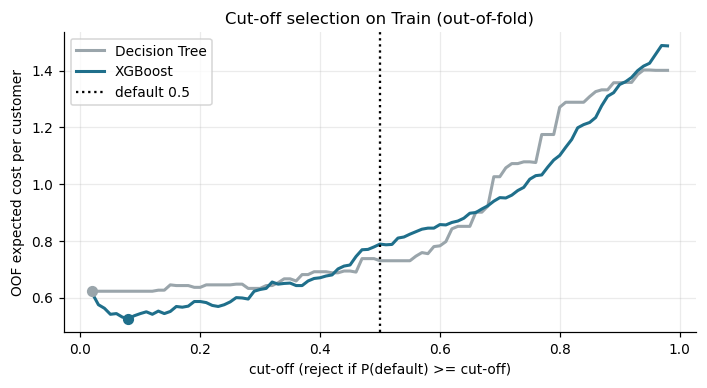

Final model chosen on Train OOF cost: XGBoost


In [11]:
#Cut-off chosen on TRAIN via out-of-fold (OOF) predictions, minimising expected cost (FP*1 + FN*5)
OOF_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)    # different folds than the tuning CV
THR = np.round(np.arange(0.02, 0.981, 0.01), 2)
def exp_cost(yt, p, thr):
    pred = (p >= thr).astype(int); fp = ((pred == 1) & (yt == 0)).sum(); fn = ((pred == 0) & (yt == 1)).sum()
    return (COST_FP * fp + COST_FN * fn) / len(yt)
oof, cutoff, cost_curve = {}, {}, {}
for nm, est in MODELS.items():
    oof[nm] = cross_val_predict(clone(est), X_train, y_train, cv=OOF_CV, method="predict_proba", n_jobs=2)[:, 1]
    cost_curve[nm] = np.array([exp_cost(y_train.values, oof[nm], t) for t in THR])
    cutoff[nm] = float(THR[cost_curve[nm].argmin()])
    print(f"{nm}: OOF-optimal cut-off = {cutoff[nm]:.2f} | OOF expected cost/customer = {cost_curve[nm].min():.3f} (at 0.50: {exp_cost(y_train.values, oof[nm], .5):.3f})")
base_cost_oof = dict(approve_all=COST_FN * y_train.mean(), reject_all=COST_FP * (1 - y_train.mean()))
print("Trivial policies on Train (cost/customer):", {k: round(v, 3) for k, v in base_cost_oof.items()})
print(f"Theoretical break-even PD for a CALIBRATED model = {COST_FP/(COST_FP+COST_FN):.3f}  (class weighting shifts probabilities, hence the empirical OOF search)")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for nm, c in zip(MODELS, [C_GREY, C_MAIN]):
    ax.plot(THR, cost_curve[nm], label=nm, color=c, lw=2); ax.scatter([cutoff[nm]], [cost_curve[nm].min()], color=c, zorder=5, s=40)
ax.axvline(.5, color="k", ls=":", label="default 0.5"); ax.set_xlabel("cut-off (reject if P(default) >= cut-off)"); ax.set_ylabel("OOF expected cost per customer")
ax.set_title("Cut-off selection on Train (out-of-fold)"); ax.legend(); fig.tight_layout(); save(fig, "cost_curve_oof")

#Final model SELECTION uses Train/OOF information only (never the Test set)
final_name = min(MODELS, key=lambda k: cost_curve[k].min())
print("Final model chosen on Train OOF cost:", final_name)
RES["cutoff"] = dict(per_model=cutoff, oof_cost={k: float(v.min()) for k, v in cost_curve.items()}, oof_cost_at_05={k: float(exp_cost(y_train.values, oof[k], .5)) for k in MODELS},
                     final_model=final_name, trivial_train=base_cost_oof, breakeven=COST_FP / (COST_FP + COST_FN),
                     curve_thr=THR.tolist(), curve={k: v.tolist() for k, v in cost_curve.items()})

<div dir="rtl" style="text-align:right">

### ۳-۳ ارزیابی روی Test: جدول مقایسه و ماتریس درهم‌ریختگی (cut-off بهینه در برابر 0.5)

</div>

,model,cutoff_type,cutoff,ROC_AUC,PR_AUC,precision,recall,f1,TN,FP,FN,TP,cost_per_customer,total_cost,reject_rate
0,Decision Tree,cost-optimal,0.02,0.744,0.534,0.352,0.933,0.511,37,103,4,56,0.615,123,0.795
1,Decision Tree,default 0.5,0.50,0.744,0.534,0.413,0.833,0.552,69,71,10,50,0.605,121,0.605
2,XGBoost,cost-optimal,0.08,0.801,0.681,0.377,0.967,0.542,44,96,2,58,0.530,106,0.770
3,XGBoost,default 0.5,0.50,0.801,0.681,0.590,0.600,0.595,115,25,24,36,0.725,145,0.305


Trivial policies on Test (cost/customer): {'approve_all': np.float64(1.5), 'reject_all': np.float64(0.7)} | PR-AUC of a random model = prevalence = 0.3
{'Decision Tree': {'roc': [0.664, 0.811], 'pr': [0.405, 0.665]}, 'XGBoost': {'roc': [0.73, 0.867], 'pr': [0.563, 0.791]}}


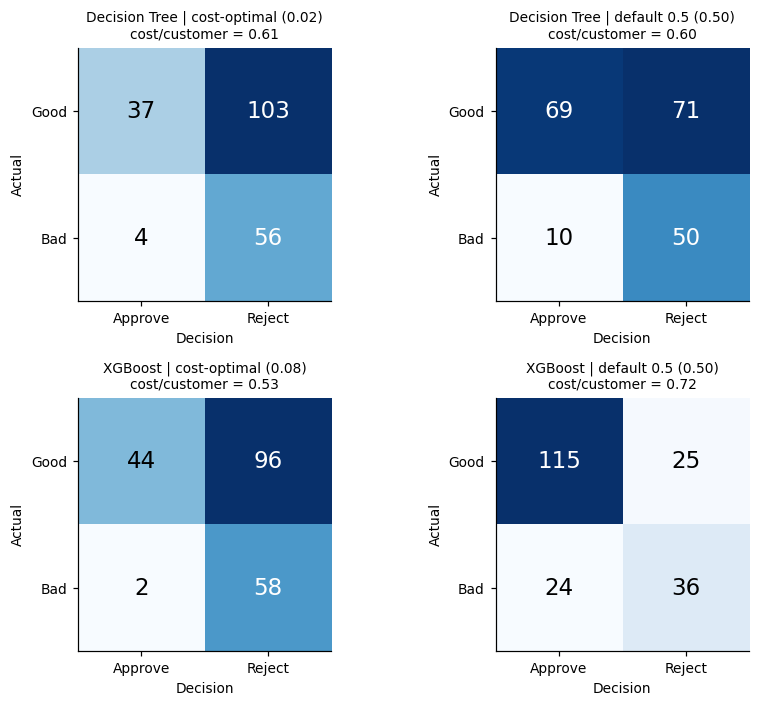

<div dir="rtl" style="text-align:right">

**هزینهٔ خطاها (ماتریس هزینهٔ german.doc):** رد کردن مشتری خوش‌حساب (FP) هزینهٔ 1 و تأیید مشتری بدحساب (FN) هزینهٔ 5 دارد؛ یعنی هر FN معادل 5 FP است.
برای مدل نهایی (`XGBoost`) روی Test در cut-off بهینهٔ 0.08: 96 خوش‌حساب رد و 2 بدحساب تأیید شد → هزینه = 106 واحد (0.53 به ازای هر متقاضی).
در cut-off پیش‌فرض 0.5: 25 FP و 24 FN → هزینه = 145 واحد (0.72 به ازای هر متقاضی).
برای مقایسه: «تأیید همه» 1.50 و «رد همه» 0.70 به ازای هر متقاضی هزینه دارد.


</div>

In [12]:
#TEST evaluation (first and only time the Test set is touched for the models)
p_test = {nm: est.predict_proba(X_test)[:, 1] for nm, est in MODELS.items()}
yt = y_test.values
def metrics_at(p, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return dict(precision=precision_score(yt, pred, zero_division=0), recall=recall_score(yt, pred), f1=f1_score(yt, pred), TN=tn, FP=fp, FN=fn, TP=tp,
                cost_per_customer=(COST_FP * fp + COST_FN * fn) / len(yt), total_cost=COST_FP * fp + COST_FN * fn, reject_rate=pred.mean())
rows = []
for nm in MODELS:
    for label, thr in [("cost-optimal", cutoff[nm]), ("default 0.5", 0.5)]:
        rows.append(dict(model=nm, cutoff_type=label, cutoff=thr, ROC_AUC=roc_auc_score(yt, p_test[nm]), PR_AUC=average_precision_score(yt, p_test[nm]), **metrics_at(p_test[nm], thr)))
test_tab = pd.DataFrame(rows); display(test_tab.round(3))
triv = dict(approve_all=COST_FN * yt.mean(), reject_all=COST_FP * (1 - yt.mean()))
print("Trivial policies on Test (cost/customer):", {k: round(v, 3) for k, v in triv.items()}, "| PR-AUC of a random model = prevalence =", round(yt.mean(), 3))

# bootstrap 95% CI of the AUCs (n_test is only 200 -> uncertainty is large)
rng = np.random.RandomState(SEED); ci = {}
for nm in MODELS:
    r, a = [], []
    for _ in range(1000):
        i = rng.randint(0, len(yt), len(yt))
        if yt[i].min() == yt[i].max(): continue
        r.append(roc_auc_score(yt[i], p_test[nm][i])); a.append(average_precision_score(yt[i], p_test[nm][i]))
    ci[nm] = dict(roc=np.percentile(r, [2.5, 97.5]).tolist(), pr=np.percentile(a, [2.5, 97.5]).tolist())
print({k: {m: [round(x, 3) for x in v] for m, v in d.items()} for k, d in ci.items()})
RES["test_table"] = test_tab.to_dict("records"); RES["test_ci"] = ci; RES["trivial_test"] = triv

#Confusion matrices: 2 models x 2 cut-offs
fig, ax = plt.subplots(2, 2, figsize=(8, 6.5))
for i, nm in enumerate(MODELS):
    for j, (label, thr) in enumerate([("cost-optimal", cutoff[nm]), ("default 0.5", .5)]):
        cm = confusion_matrix(yt, (p_test[nm] >= thr).astype(int), labels=[0, 1]); a = ax[i, j]; a.imshow(cm, cmap="Blues"); a.grid(False)
        for u in range(2):
            for v in range(2): a.text(v, u, str(cm[u, v]), ha="center", va="center", fontsize=15, color="white" if cm[u, v] > cm.max() / 2 else "black")
        a.set_xticks([0, 1]); a.set_xticklabels(["Approve", "Reject"]); a.set_yticks([0, 1]); a.set_yticklabels(["Good", "Bad"]); a.set_xlabel("Decision"); a.set_ylabel("Actual")
        a.set_title(f"{nm} | {label} ({thr:.2f})\ncost/customer = {(COST_FP*cm[0,1]+COST_FN*cm[1,0])/len(yt):.2f}", fontsize=9)
fig.tight_layout(); save(fig, "confusion_matrices")
fm = final_name; r = test_tab[(test_tab.model == fm) & (test_tab.cutoff_type == "cost-optimal")].iloc[0]; r5 = test_tab[(test_tab.model == fm) & (test_tab.cutoff_type == "default 0.5")].iloc[0]
rtl(f"""**هزینهٔ خطاها (ماتریس هزینهٔ german.doc):** رد کردن مشتری خوش‌حساب (FP) هزینهٔ {COST_FP} و تأیید مشتری بدحساب (FN) هزینهٔ {COST_FN} دارد؛ یعنی هر FN معادل {COST_FN//COST_FP} FP است.
برای مدل نهایی (`{fm}`) روی Test در cut-off بهینهٔ {cutoff[fm]:.2f}: {int(r.FP)} خوش‌حساب رد و {int(r.FN)} بدحساب تأیید شد → هزینه = {r.total_cost:.0f} واحد ({r.cost_per_customer:.2f} به ازای هر متقاضی).
در cut-off پیش‌فرض 0.5: {int(r5.FP)} FP و {int(r5.FN)} FN → هزینه = {r5.total_cost:.0f} واحد ({r5.cost_per_customer:.2f} به ازای هر متقاضی).
برای مقایسه: «تأیید همه» {triv['approve_all']:.2f} و «رد همه» {triv['reject_all']:.2f} به ازای هر متقاضی هزینه دارد.
""")

<div dir="rtl" style="text-align:right">

**مبادلهٔ FP و FN به زبان پول:** FP یعنی رد مشتری خوش‌حساب؛ هزینه‌اش سودِ از دست‌رفته (حاشیه سود/بهرهٔ وام) است و در ماتریس هزینه ۱ واحد گرفته شده. FN یعنی تأیید مشتری بدحساب؛ هزینه‌اش بخش بزرگی از اصل وام است (زیان نکول) و ۵ واحد است. چون خطای FN پنج برابر گران‌تر است، cut-off بهینه پایین‌تر از ۰٫۵ است: بانک ترجیح می‌دهد چند مشتری خوب را رد کند تا یک بدحساب را نپذیرد. (نقطهٔ سربه‌سر نظری برای مدل کالیبره = ۱/(۱+۵) ≈ ۰٫۱۷ است.)

</div>

<div dir="rtl" style="text-align:right">

### ۳-۴ اثر حذف متغیرهای حساس و ویژگی‌های مهندسی‌شده + یادداشت انصاف

</div>

In [13]:
#Effect of excluding sensitive attributes (and of the engineered features). Same protocol: tuned on Train CV only.
# NOTE: Test numbers below are INFORMATION ONLY - no choice is made from them.
scen = {"all features (main benchmark)": (False, True), "without sensitive attributes": (True, True), "without engineered features": (False, False)}
abl = []
for sname, (ds, fe) in scen.items():
    d, x = (dt_search, xgb_search) if sname.startswith("all") else tune_models(ds, fe)
    for mn, s in [("Decision Tree", d), ("XGBoost", x)]:
        pt = s.best_estimator_.predict_proba(X_test)[:, 1]
        abl.append(dict(scenario=sname, model=mn, **{k: v for k, v in cv_summary(s).items() if k in ("cv_pr_auc", "cv_roc_auc")},
                        test_pr_auc=average_precision_score(yt, pt), test_roc_auc=roc_auc_score(yt, pt)))
abl_tab = pd.DataFrame(abl); display(abl_tab.round(3)); RES["ablation"] = abl_tab.to_dict("records")

#Fairness snapshot on Test for the final model at its cost-optimal cut-off (reference only; groups are small)
pf = p_test[final_name]; rej = pf >= cutoff[final_name]; Xt = X_test.copy()
Xt["sex"] = np.where(Xt.personal_status_sex.isin(["A92", "A95"]), "female", "male"); Xt["age_group"] = pd.cut(Xt.age, [0, 25, 40, 120], labels=["<=25", "26-40", ">40"], right=True)
Xt["foreign"] = Xt.foreign_worker.map({"A201": "foreign worker", "A202": "not foreign"})
fair = []
for g in ["sex", "age_group", "foreign"]:
    for k, idx in Xt.groupby(g, observed=True).groups.items():
        m_ = Xt.index.get_indexer(idx); fair.append(dict(attribute=g, group=str(k), n=len(m_), reject_rate=rej[m_].mean(), actual_default_rate=yt[m_].mean()))
fair_tab = pd.DataFrame(fair); display(fair_tab.round(3)); RES["fairness"] = fair_tab.to_dict("records")
a = abl_tab; m0 = a[(a.scenario.str.startswith("all")) & (a.model == "XGBoost")].iloc[0]; m1 = a[(a.scenario.str.startswith("without sens")) & (a.model == "XGBoost")].iloc[0]
rtl(f"""**یادداشت انصاف و الزامات مقررات‌گذاری:** سه ویژگی `personal_status_sex`، `age` و `foreign_worker` مشخصات حساس/حفاظت‌شده‌اند؛ در بسیاری از نظام‌های حقوقی (مانند ECOA در آمریکا، GDPR و قوانین ضدتبعیض در اتحادیهٔ اروپا) استفاده از آن‌ها در تصمیم اعتباری ممنوع یا به‌شدت محدود است
و حتی با حذف مستقیم، «متغیرهای نیابتی» (proxy) مانند شغل یا مسکن می‌توانند اثر تبعیضی را بازتولید کنند. در این پروژه آن‌ها فقط برای **بنچمارک** نگه داشته شده‌اند و نتیجهٔ حذفشان گزارش می‌شود.
برای چالشگر (XGBoost): CV PR-AUC با حساس‌ها = {m0.cv_pr_auc:.3f} و بدون آن‌ها = {m1.cv_pr_auc:.3f} (اختلاف {m1.cv_pr_auc-m0.cv_pr_auc:+.3f})؛ ROC-AUC روی Train-CV: {m0.cv_roc_auc:.3f} در برابر {m1.cv_roc_auc:.3f}.
اعداد Test در جدول بالا صرفاً اطلاعاتی‌اند و هیچ انتخابی بر پایهٔ آن‌ها انجام نشده است. جدول انصاف نیز به دلیل کوچک بودن گروه‌ها فقط جنبهٔ راهنما دارد.
""")

,scenario,model,cv_pr_auc,cv_roc_auc,test_pr_auc,test_roc_auc
0,all features (main benchmark),Decision Tree,0.492,0.702,0.534,0.744
1,all features (main benchmark),XGBoost,0.622,0.793,0.681,0.801
2,without sensitive attributes,Decision Tree,0.506,0.714,0.533,0.745
3,without sensitive attributes,XGBoost,0.633,0.797,0.705,0.800
4,without engineered features,Decision Tree,0.506,0.727,0.592,0.739
5,without engineered features,XGBoost,0.624,0.798,0.627,0.794


,attribute,group,n,reject_rate,actual_default_rate
0,sex,female,61,0.836,0.328
1,sex,male,139,0.741,0.288
2,age_group,<=25,44,0.886,0.455
3,age_group,26-40,92,0.761,0.293
4,age_group,>40,64,0.703,0.203
5,foreign,foreign worker,194,0.784,0.304
6,foreign,not foreign,6,0.333,0.167


<div dir="rtl" style="text-align:right">

**یادداشت انصاف و الزامات مقررات‌گذاری:** سه ویژگی `personal_status_sex`، `age` و `foreign_worker` مشخصات حساس/حفاظت‌شده‌اند؛ در بسیاری از نظام‌های حقوقی (مانند ECOA در آمریکا، GDPR و قوانین ضدتبعیض در اتحادیهٔ اروپا) استفاده از آن‌ها در تصمیم اعتباری ممنوع یا به‌شدت محدود است
و حتی با حذف مستقیم، «متغیرهای نیابتی» (proxy) مانند شغل یا مسکن می‌توانند اثر تبعیضی را بازتولید کنند. در این پروژه آن‌ها فقط برای **بنچمارک** نگه داشته شده‌اند و نتیجهٔ حذفشان گزارش می‌شود.
برای چالشگر (XGBoost): CV PR-AUC با حساس‌ها = 0.622 و بدون آن‌ها = 0.633 (اختلاف +0.010)؛ ROC-AUC روی Train-CV: 0.793 در برابر 0.797.
اعداد Test در جدول بالا صرفاً اطلاعاتی‌اند و هیچ انتخابی بر پایهٔ آن‌ها انجام نشده است. جدول انصاف نیز به دلیل کوچک بودن گروه‌ها فقط جنبهٔ راهنما دارد.


</div>

<div dir="rtl" style="text-align:right">

### ۳-۵ توضیح‌پذیری با SHAP (چالشگر XGBoost): تحلیل سراسری

</div>

SHAP values: (200, 50) | base value (log-odds): 0.5762225985527039


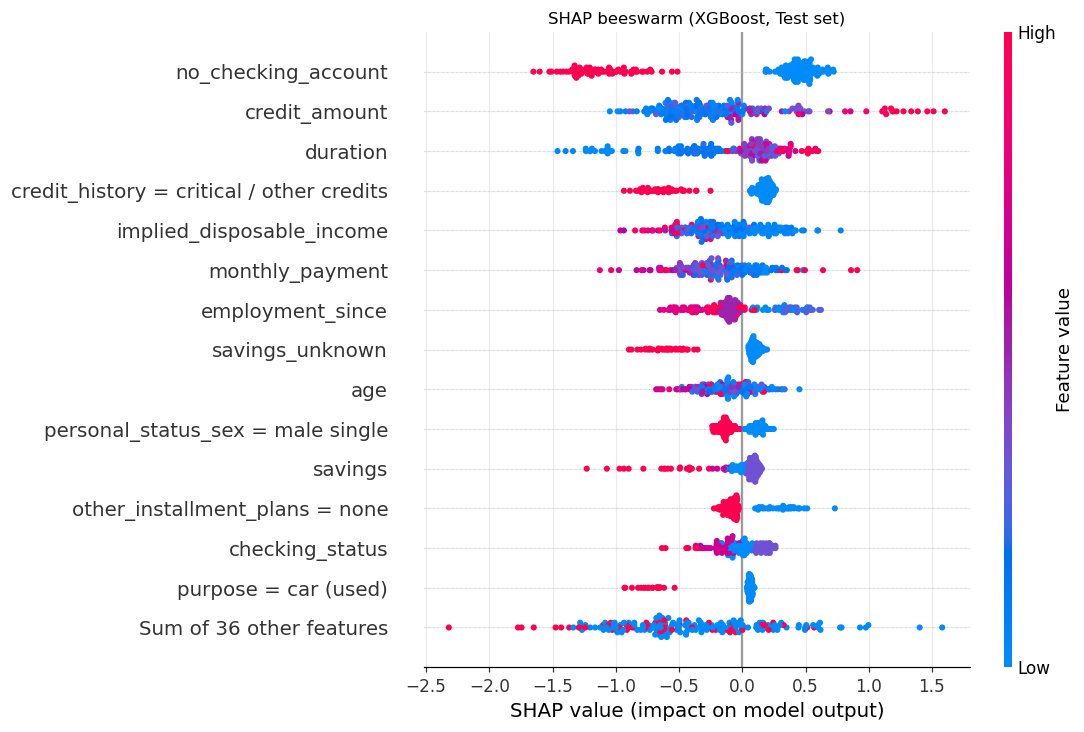

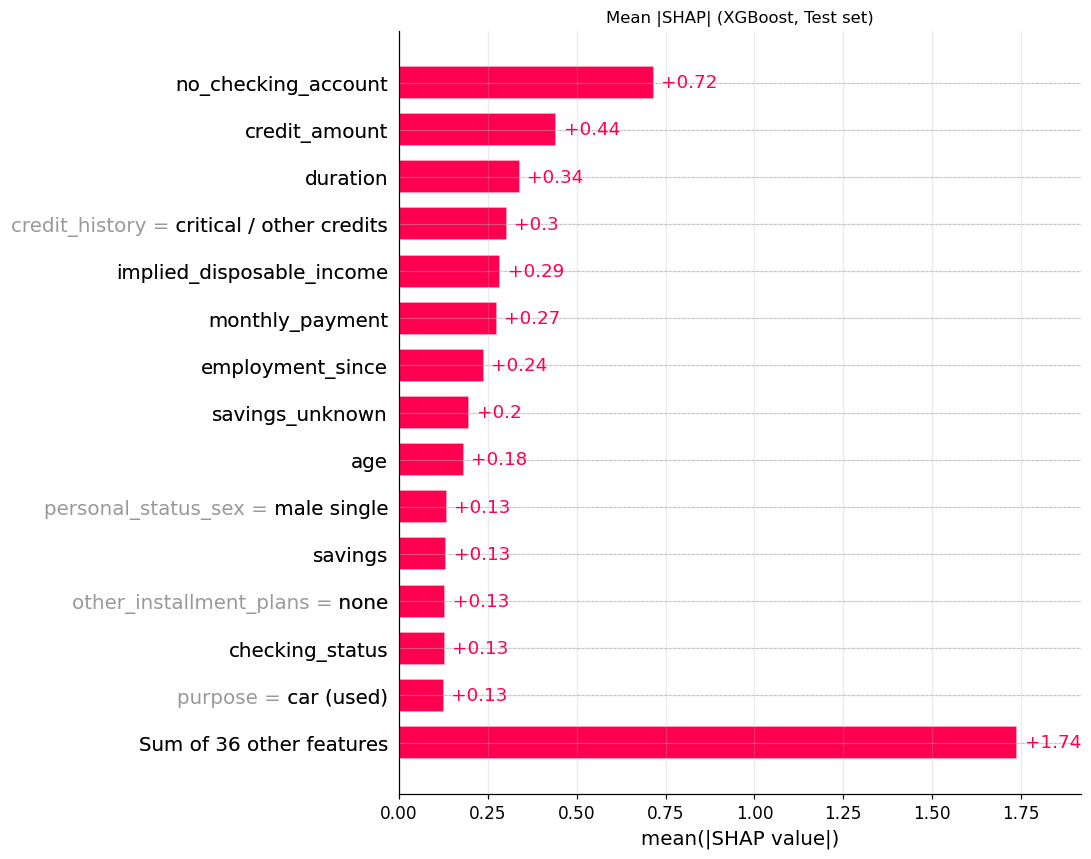

,mean|SHAP|
no_checking_account,0.718
credit_amount,0.443
duration,0.340
credit_history = critical / other credits,0.304
implied_disposable_income,0.285
monthly_payment,0.275
employment_since,0.238
savings_unknown,0.198
age,0.184
personal_status_sex = male single,0.135


<div dir="rtl" style="text-align:right">

**تفسیر سراسری:** مهم‌ترین عوامل (میانگین |SHAP|): `no_checking_account` (0.72)، `credit_amount` (0.44)، `duration` (0.34)، `credit_history = critical / other credits` (0.30)، `implied_disposable_income` (0.29)، `monthly_payment` (0.27). در نمودار beeswarm هر نقطه یک متقاضی است؛ نقاط سمت راست ریسک نکول را بالا می‌برند و رنگ قرمز یعنی مقدار زیاد ویژگی.

</div>

In [14]:
import shap
xgb_pipe = MODELS["XGBoost"]                        # SHAP is computed on the challenger, as required
pre = xgb_pipe[:-1]; booster = xgb_pipe[-1]
fn_raw = list(xgb_pipe.named_steps["pre"][-1].get_feature_names_out())
def pretty(name):
    for c in NOMINAL:
        if name.startswith(c + "_"): return f"{c} = {LABELS[c].get(name[len(c)+1:], name[len(c)+1:])}"
    return name
fnames = [pretty(n) for n in fn_raw]
Xte_t = pd.DataFrame(pre.transform(X_test), columns=fnames, index=X_test.index)
explainer = shap.TreeExplainer(booster)
sv = explainer(Xte_t)                               # log-odds contributions, explanation of P(default)
sv.feature_names = fnames
print("SHAP values:", sv.values.shape, "| base value (log-odds):", float(np.ravel(sv.base_values)[0]))

plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False); plt.title("SHAP beeswarm (XGBoost, Test set)"); save(plt.gcf(), "shap_beeswarm")
plt.figure(); shap.plots.bar(sv, max_display=15, show=False); plt.title("Mean |SHAP| (XGBoost, Test set)"); save(plt.gcf(), "shap_bar")
imp = pd.Series(np.abs(sv.values).mean(0), index=fnames).sort_values(ascending=False); display(imp.head(12).round(3).to_frame("mean|SHAP|"))
signed = pd.Series([np.corrcoef(Xte_t.iloc[:, i], sv.values[:, i])[0, 1] if Xte_t.iloc[:, i].std() > 0 else 0 for i in range(len(fnames))], index=fnames)
RES["shap_global"] = [dict(feature=f, mean_abs=float(imp[f]), direction_corr=float(signed[f])) for f in imp.head(12).index]
rtl("**تفسیر سراسری:** مهم‌ترین عوامل (میانگین |SHAP|): " + "، ".join(f"`{f}` ({imp[f]:.2f})" for f in imp.head(6).index) +
    ". در نمودار beeswarm هر نقطه یک متقاضی است؛ نقاط سمت راست ریسک نکول را بالا می‌برند و رنگ قرمز یعنی مقدار زیاد ویژگی.")

<div dir="rtl" style="text-align:right">

### ۳-۶ تحلیل موردی (Waterfall): یک مشتری تأییدشدهٔ کم‌ریسک و یک مشتری ردشدهٔ پرریسک

</div>

Approved case: Test row 12, P(default)=0.003 (cut-off 0.08), actual=good
Rejected case: Test row 37, P(default)=0.976, rejected=True, actual=bad


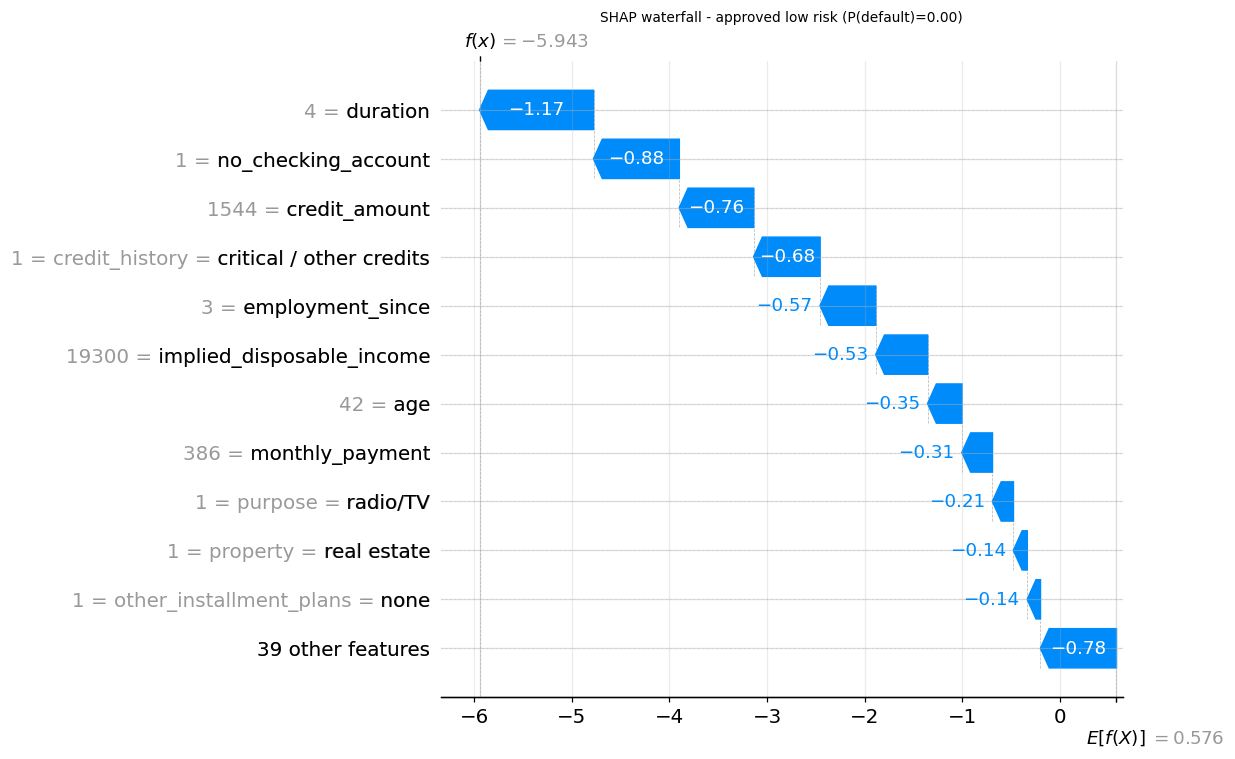

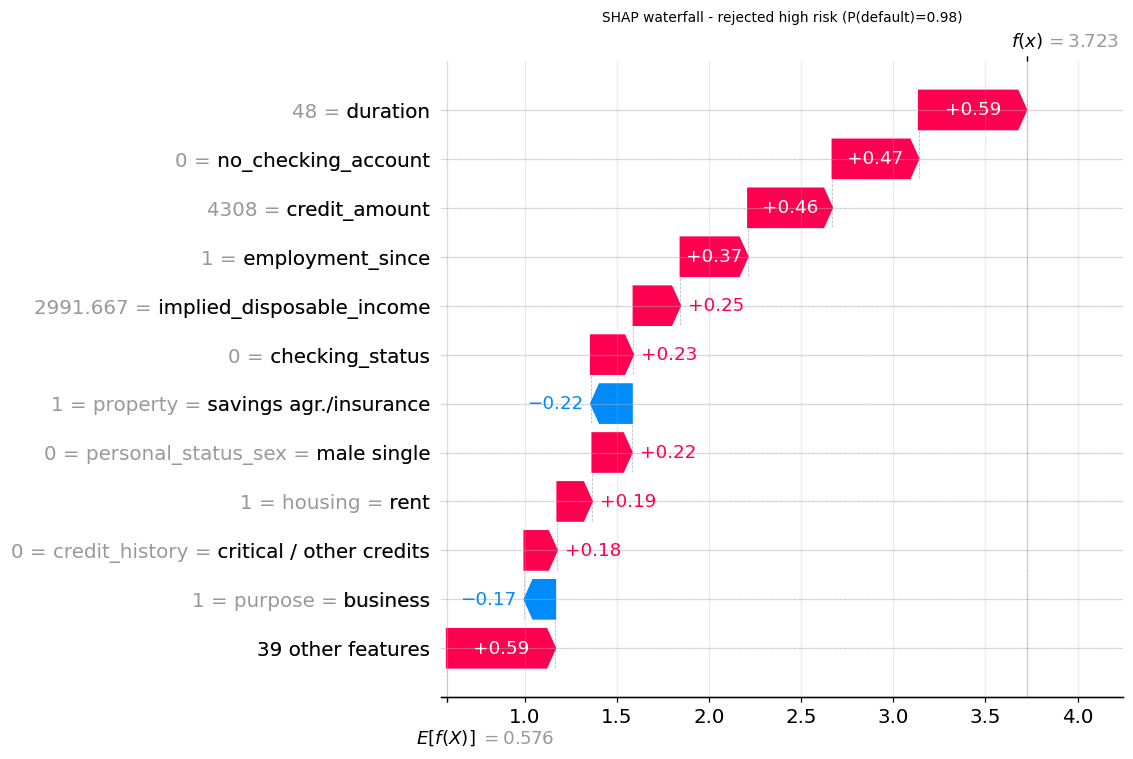

<div dir="rtl" style="text-align:right">

**تفسیر موردی (علامت + یعنی افزایش ریسک نکول، − یعنی کاهش، در مقیاس log-odds):**

- **مشتری تأییدشده با ریسک پایین** (ردیف Test 12، P(default)=0.3%، وضعیت واقعی: خوش‌حساب): عوامل اصلی = `duration` (−1.17)؛ `no_checking_account` (−0.88)؛ `credit_amount` (−0.76)؛ `credit_history = critical / other credits` (−0.68)؛ `employment_since` (−0.57)
- **مشتری ردشده با ریسک بالا** (ردیف Test 37، P(default)=97.6%، وضعیت واقعی: بدحساب): عوامل اصلی = `duration` (+0.59)؛ `no_checking_account` (+0.47)؛ `credit_amount` (+0.46)؛ `employment_since` (+0.37)؛ `implied_disposable_income` (+0.25)

</div>

,234,11
checking_status,A14,A11
duration,4,48
credit_history,A34,A32
purpose,A43,A49
credit_amount,1544,4308
savings,A61,A61
employment_since,A74,A72
installment_rate,2,3
personal_status_sex,A93,A92
other_debtors,A101,A101


In [15]:
#Two Test cases chosen by predicted risk only (labels are NOT used for the choice)
pt_x = p_test["XGBoost"]; thr_x = cutoff["XGBoost"]
i_ok = int(np.argmin(pt_x))                                   # most confidently approved (lowest P(default))
i_rej = int(np.argmax(pt_x))                                  # most confidently rejected (highest P(default)); also >= cut-off
print(f"Approved case: Test row {i_ok}, P(default)={pt_x[i_ok]:.3f} (cut-off {thr_x:.2f}), actual={'bad' if yt[i_ok] else 'good'}")
print(f"Rejected case: Test row {i_rej}, P(default)={pt_x[i_rej]:.3f}, rejected={pt_x[i_rej] >= thr_x}, actual={'bad' if yt[i_rej] else 'good'}")
for tag, i in [("approved_low_risk", i_ok), ("rejected_high_risk", i_rej)]:
    plt.figure(); shap.plots.waterfall(sv[i], max_display=12, show=False); plt.title(f"SHAP waterfall - {tag.replace('_', ' ')} (P(default)={pt_x[i]:.2f})", fontsize=9)
    save(plt.gcf(), f"shap_waterfall_{tag}")

def top_factors(i, k=6):
    s = pd.Series(sv.values[i], index=fnames); return s.reindex(s.abs().sort_values(ascending=False).index).head(k)
def describe_case(i, name):
    f = top_factors(i, 5); raw_row = X_test.iloc[i]
    txt = "؛ ".join(f"`{n}` ({'+' if v > 0 else '−'}{abs(v):.2f})" for n, v in f.items())
    return f"- **{name}** (ردیف Test {i}، P(default)={pt_x[i]:.1%}، وضعیت واقعی: {'بدحساب' if yt[i] else 'خوش‌حساب'}): عوامل اصلی = {txt}"
cases = {"approved": dict(row=i_ok, p=float(pt_x[i_ok]), actual=int(yt[i_ok]), top=[(n, float(v)) for n, v in top_factors(i_ok).items()]),
         "rejected": dict(row=i_rej, p=float(pt_x[i_rej]), actual=int(yt[i_rej]), top=[(n, float(v)) for n, v in top_factors(i_rej).items()])}
RES["cases"] = cases
rtl("**تفسیر موردی (علامت + یعنی افزایش ریسک نکول، − یعنی کاهش، در مقیاس log-odds):**\n\n" + describe_case(i_ok, "مشتری تأییدشده با ریسک پایین") + "\n" + describe_case(i_rej, "مشتری ردشده با ریسک بالا"))
display(X_test.iloc[[i_ok, i_rej]].assign(P_default=pt_x[[i_ok, i_rej]]).T)

<div dir="rtl" style="text-align:right">

### ۳-۷ بونوس (LLM): پرامپت قابل‌استفادهٔ مجدد برای توضیح رد درخواست
پرامپت زیر عوامل SHAP **واقعی** مشتری ردشده را می‌گیرد؛ عوامل مربوط به ویژگی‌های حساس قبل از ورود به پرامپت حذف می‌شوند و در متن مشتری هم هرگز SHAP/امتیاز/ویژگی حساس ذکر نمی‌شود.

</div>

In [16]:
#BONUS: reusable LLM prompt, filled with the REAL SHAP output of the rejected case
SENSITIVE_NAMES = ("age", "personal_status_sex", "foreign_worker")       # never exposed to the customer text
def human_value(fname, i):
    row = X_test.iloc[i]
    if fname in LABELS_CAT_COLS:                       # ordinal categorical kept as one column (checking_status, savings, ...)
        return LABELS[fname][row[fname]]
    if fname == "no_checking_account":
        return "no checking account" if Xte_t.iloc[i][fname] == 1 else f"has a checking account, balance status: {LABELS['checking_status'][row['checking_status']]}"
    if fname == "savings_unknown":
        return "savings unknown/none" if Xte_t.iloc[i][fname] == 1 else f"savings known: {LABELS['savings'][row['savings']]}"
    if " = " in fname: return "yes (applies to this customer)"
    if fname in row.index: return f"{row[fname]:g}"
    return f"{Xte_t.iloc[i][fname]:.2f}"
LABELS_CAT_COLS = list(LABELS.keys())

PLAIN = {"no_checking_account": "checking-account situation", "savings_unknown": "savings situation",
         "implied_disposable_income": "estimated disposable income (derived from instalment share)", "monthly_payment": "estimated monthly instalment",
         "duration": "loan duration (months)", "credit_amount": "loan amount (DM)", "employment_since": "time in current employment"}
def factor_table(i, k=5):
    out = []
    for n, v in pd.Series(sv.values[i], index=fnames).sort_values(key=abs, ascending=False).items():
        if n.split(" = ")[0] in SENSITIVE_NAMES: continue
        out.append(dict(feature=PLAIN.get(n, n), value=human_value(n, i), direction="increases default risk" if v > 0 else "decreases default risk", magnitude=round(float(v), 3)))
        if len(out) == k: break
    return out

PROMPT_TEMPLATE = """You are a courteous customer-communication assistant for a consumer lender.
A loan application was declined by our credit-scoring process. Using ONLY the factors below, write a short message to the applicant.

LOAN CONTEXT
- Requested amount (DM): {amount}
- Requested duration (months): {duration}

DECISION FACTORS (ordered by importance; direction = effect on the applicant's default risk; magnitude = relative strength)
{factors}

WHAT TO PRODUCE (in {language}, max 180 words, warm and respectful tone, no jargon)
1. EXPLAIN politely why the application could not be approved this time. Mention only the 2-3 strongest risk-increasing factors, in everyday words.
2. GIVE 3-4 concrete, actionable steps the applicant can take in the coming 3-12 months to improve creditworthiness
   (for example: keep the current account in credit, build a savings buffer, request a smaller amount or shorter term, add a guarantor/co-applicant).
   Each step must map to one of the factors above. Do not promise approval.

HARD RULES
- NEVER mention SHAP, scores, probabilities, models, algorithms or numbers such as "magnitude".
- NEVER mention or hint at age, gender, marital status, nationality/foreign-worker status or any other personal characteristic.
- Do not blame the applicant; do not give legal or investment advice; end with an invitation to re-apply or to speak with an advisor."""

ft = factor_table(i_rej)
factors_txt = "\n".join(f"- feature: {d['feature']} | value: {d['value']} | direction: {d['direction']} | magnitude: {d['magnitude']:+.3f}" for d in ft)
filled_prompt = PROMPT_TEMPLATE.format(amount=int(X_test.iloc[i_rej]["credit_amount"]), duration=int(X_test.iloc[i_rej]["duration"]), factors=factors_txt, language="Persian (Farsi)")
RES["llm_factors"] = ft
print(filled_prompt)

You are a courteous customer-communication assistant for a consumer lender.
A loan application was declined by our credit-scoring process. Using ONLY the factors below, write a short message to the applicant.

LOAN CONTEXT
- Requested amount (DM): 4308
- Requested duration (months): 48

DECISION FACTORS (ordered by importance; direction = effect on the applicant's default risk; magnitude = relative strength)
- feature: loan duration (months) | value: 48 | direction: increases default risk | magnitude: +0.585
- feature: checking-account situation | value: has a checking account, balance status: < 0 DM | direction: increases default risk | magnitude: +0.469
- feature: loan amount (DM) | value: 4308 | direction: increases default risk | magnitude: +0.458
- feature: time in current employment | value: < 1 yr | direction: increases default risk | magnitude: +0.366
- feature: estimated disposable income (derived from instalment share) | value: 2991.67 | direction: increases default risk | ma

<div dir="rtl" style="text-align:right">

**نمونه پیام تولیدشده برای مشتری** (نوشته‌شده بر اساس همین پرامپت و خروجی واقعی SHAP بالا؛ فراخوانی زندهٔ LLM انجام نشده است):

> مشتری گرامی، از اینکه برای دریافت تسهیلات به ما اعتماد کردید سپاسگزاریم. پس از بررسی دقیق، متأسفانه این بار نتوانستیم درخواست شما را تأیید کنیم. مهم‌ترین دلایل این بود که حساب جاری شما در حال حاضر مانده منفی دارد، مدت بازپرداخت درخواستی (۴۸ ماه) بسیار طولانی است و مبلغ وام نسبت به سابقهٔ کاری فعلی شما (کمتر از یک سال) سنگین‌تر از حد مطمئن ارزیابی شد.
>
> کارهایی که می‌توانید در ۳ تا ۱۲ ماه آینده انجام دهید:
> 1. مانده حساب جاری خود را به بالای صفر برسانید و چند ماه پیاپی مثبت نگه دارید.
> 2. اگر ممکن است مبلغ یا مدت درخواستی را کمتر کنید؛ مثلاً وام کوتاه‌تر با قسط قابل‌مدیریت‌تر.
> 3. هر ماه مبلغ کوچکی را پس‌انداز کنید تا یک پشتوانهٔ مالی بسازید.
> 4. پس از تثبیت سابقهٔ شغلی فعلی (حداقل یک سال)، دوباره درخواست دهید؛ در صورت امکان، داشتن ضامن یا هم‌وام‌گیرنده نیز می‌تواند کمک کند.
>
> ما تضمینی برای تأیید نمی‌دهیم، اما خوشحال می‌شویم پس از این اقدامات درخواست شما را دوباره بررسی کنیم. برای مشورت می‌توانید با کارشناسان ما تماس بگیرید.

</div>

<div dir="rtl" style="text-align:right">

## گام ۴ — علیت در برابر همبستگی
مدل و SHAP فقط **همبستگی‌های پیش‌بینی‌کننده** را توصیف می‌کنند؛ مقدار SHAP بالا یعنی «مدل از این ویژگی برای پیش‌بینی استفاده می‌کند» و نه «تغییر این ویژگی نکول را تغییر می‌دهد». جدول زیر ۱۲ عامل برتر را بر اساس قضاوت تحلیل‌گر دسته‌بندی می‌کند.

</div>

In [17]:
#Classify the top SHAP drivers: plausible causal lever vs. correlational signal (analyst judgement, documented)
JUDGE = {
 "checking_status": ("signal + partial cause", "Reflects liquidity/behaviour; the balance itself is not a lever, but customers can build it."),
 "no_checking_account": ("signal (selection)", "'No account' mostly marks a different customer segment/channel, not a risk cause."),
 "duration": ("plausible lever", "Longer exposure = more time for shocks; the lender controls the term."),
 "credit_amount": ("plausible lever", "Amount relative to capacity raises burden; limit is controlled by the lender."),
 "monthly_payment": ("plausible lever", "Repayment burden depends on amount/term - both set by policy."),
 "implied_disposable_income": ("proxy for unobserved income", "Derived from instalment %; a noisy income proxy, confounded by true income."),
 "credit_history": ("signal (past behaviour)", "Past behaviour predicts future behaviour but is not itself manipulable; may encode selection."),
 "savings": ("partial cause / signal", "A buffer helps absorb shocks (causal), but also marks unobserved wealth (confounder)."),
 "savings_unknown": ("signal (selection)", "Unknown savings is a data-collection artefact."),
 "employment_since": ("confounded signal", "Tenure is entangled with age, job type and income."),
 "age": ("confounded + SENSITIVE", "Proxy for experience/income/life stage; must not be used as a lever."),
 "housing": ("confounded signal", "Owning vs renting proxies wealth, age and stability."),
 "stability_flag": ("confounded signal", "Combination of tenure and housing; correlates with age and wealth."),
 "property": ("confounded signal", "Wealth proxy; 'unknown' category is a missing-data artefact."),
 "purpose": ("mixed", "Purpose may change use of funds, but also marks customer segment."),
 "other_debtors": ("plausible lever (loss)", "A guarantor/co-applicant lowers loss given default - requirable by policy."),
 "other_installment_plans": ("signal", "Existing debt load elsewhere; a leverage proxy."),
 "installment_rate": ("plausible lever", "Instalment burden is set at origination."),
 "job": ("confounded signal", "Entangled with income and education."),
 "foreign_worker": ("SENSITIVE proxy", "Must not be used for decisions."), "personal_status_sex": ("SENSITIVE", "Must not be used for decisions."),
 "telephone": ("pure signal", "Landline ownership is a 1990s socio-economic marker, not a cause."),
 "residence_since": ("confounded signal", "Entangled with age."), "existing_credits": ("signal", "Debt-load proxy."), "num_dependents": ("signal", "Household proxy."),
}
def judge(f):
    base = f.split(" = ")[0]; return JUDGE.get(base, ("needs review", "-"))
causal_tab = pd.DataFrame([dict(feature=f, mean_abs_shap=round(float(imp[f]), 3), class_=judge(f)[0], rationale=judge(f)[1]) for f in imp.head(12).index])
display(causal_tab)
RES["causal_table"] = causal_tab.to_dict("records")

,feature,mean_abs_shap,class_,rationale
0,no_checking_account,0.718,signal (selection),'No account' mostly marks a different customer...
1,credit_amount,0.443,plausible lever,Amount relative to capacity raises burden; lim...
2,duration,0.340,plausible lever,Longer exposure = more time for shocks; the le...
3,credit_history = critical / other credits,0.304,signal (past behaviour),Past behaviour predicts future behaviour but i...
4,implied_disposable_income,0.285,proxy for unobserved income,Derived from instalment %; a noisy income prox...
5,monthly_payment,0.275,plausible lever,Repayment burden depends on amount/term - both...
6,employment_since,0.238,confounded signal,"Tenure is entangled with age, job type and inc..."
7,savings_unknown,0.198,signal (selection),Unknown savings is a data-collection artefact.
8,age,0.184,confounded + SENSITIVE,Proxy for experience/income/life stage; must n...
9,personal_status_sex = male single,0.135,SENSITIVE,Must not be used for decisions.


<div dir="rtl" style="text-align:right">

### الف) متغیرهای با اثر علی محتمل در برابر سیگنال‌های همبسته
- **اثر علی محتمل (اهرم‌های تحت کنترل وام‌دهنده):** `credit_amount`، `duration` و در نتیجه `monthly_payment` / `installment_rate` — بار بازپرداخت و مدت مواجههٔ ریسک را مستقیماً تعیین می‌کنند؛ و داشتن ضامن/هم‌وام‌گیرنده (`other_debtors`) که زیان در صورت نکول را کم می‌کند. پس‌انداز (`savings`) نیز تا حدی علّی است چون بافر در برابر شوک درآمدی ایجاد می‌کند.
- **سیگنال‌های همبسته (نه لزوماً علی):** `credit_history` (رفتار گذشته)، `checking_status` (نشانگر نقدینگی و رفتار مالی)، `telephone`، `purpose`، `property`.
- **مخدوش‌گرها (Confounders) با مثال‌های همین داده:** `age` با `employment_since`، `housing` و `job` درهم‌تنیده است؛ مثلاً مالکیت مسکن و سابقهٔ کار بلند هر دو با سن بالاتر و درآمد بالاتر (که **مشاهده نشده** است) همبسته‌اند، پس اثر ظاهری «مالک مسکن ⇒ ریسک کمتر» ممکن است در واقع اثر «درآمد/ثروت پنهان» باشد. همچنین `checking_status = بدون حساب` ممکن است نشان‌دهندهٔ نوع مشتری یا کانال جذب باشد نه اینکه نداشتن حساب باعث نکول کم شود (سوگیری انتخاب).
- **متغیرهای حساس:** `age`، `personal_status_sex`، `foreign_worker` اهرم سیاستی نیستند و استفادهٔ تصمیم‌گیرنده از آن‌ها ممنوع/پرمخاطره است.

### ب) چه اهرم‌هایی را مدیر ریسک می‌تواند با اطمینان بیشتر به کار گیرد؟
سقف مبلغ، کوتاه‌کردن مدت یا بازساختار اقساط، قیمت‌گذاری ریسک‌محور (نرخ بهره)، الزام ضامن/هم‌وام‌گیرنده، و برنامه‌های آموزش مالی/تشویق پس‌انداز. این اهرم‌ها مستقیماً بار بازپرداخت یا زیان در صورت نکول را تغییر می‌دهند. **اما** حتی برای آن‌ها باید با آزمایش کنترل‌شده (A/B یا آزمون تصادفی کوچک) اثر علّی سنجیده شود.

### پ) چرا سیاست‌گذاری بر پایهٔ متغیرهای صرفاً همبسته خطرناک است؟
1. **سوگیری انتخاب:** داده فقط متقاضیان تأییدشدهٔ قبلی را دارد؛ رابطه‌ها ممکن است محصول فیلتر تأیید گذشته باشند (reject inference نداریم).
2. **بازخورد نامطلوب (Adverse feedback / Goodhart):** اگر مثلاً «داشتن تلفن» یا «مالکیت مسکن» را پاداش دهیم، متقاضیان خود را شبیه آن‌ها نشان می‌دهند یا بازار تغییر می‌کند و رابطه می‌شکند؛ رد مداوم گروه‌ها هم داده‌ای از آن‌ها برای یادگیری باقی نمی‌گذارد.
3. **تبعیض:** متغیرهای نیابتی (سن، جنسیت، تابعیت، شغل، مسکن) می‌توانند ناعادلانه گروه‌های حفاظت‌شده را حذف کنند.
4. **رانش (Drift):** رابطه‌های همبسته با تغییر اقتصاد/رفتار ناپایدارند؛ رابطه‌های علّی پایدارترند.

> **محدودیت بنیادی:** داده‌های مشاهداتی به‌تنهایی نمی‌توانند اثر علّی را ثابت کنند؛ برای این کار به آزمایش تصادفی، شبه‌آزمایش یا مدل‌های علّی با فرض‌های صریح نیاز است. تمام ادعاهای این بخش «محتمل» هستند، نه اثبات‌شده.

</div>